# Applied AI Mid-Term — SRGAN Results Report
**Behafarin (Behi) Emam** · `bemam`

This notebook shows the outputs of the pipeline in `src/` (run with `run_all.sh`). It doesn't train
anything. It loads the figures and tables saved in `outputs/` and displays them, in pipeline order.

In [1]:
import os, glob
import pandas as pd
from IPython.display import Image, display, Markdown
OUT = os.environ.get("OUTPUT_DIR", "outputs")
FIG, RES = os.path.join(OUT, "figures"), os.path.join(OUT, "results")
def show(name, width=1000):
    p = os.path.join(FIG, name)
    display(Image(p, width=width)) if os.path.exists(p) else print("missing:", p)
def table(name):
    p = os.path.join(RES, name)
    return pd.read_csv(p).round(4) if os.path.exists(p) else print("missing:", p)

## 1. Dataset split (stratified 70 / 30)

In [2]:
table("split_table.csv")

,split,cat,dog,total
0,train (70%),8730,8721,17451
1,train-fit,7857,7848,15705
2,validation (10% of train),873,873,1746
3,test (30%),3742,3737,7479


## 2. Examples of scaled images (128×128 vs. 32×32)

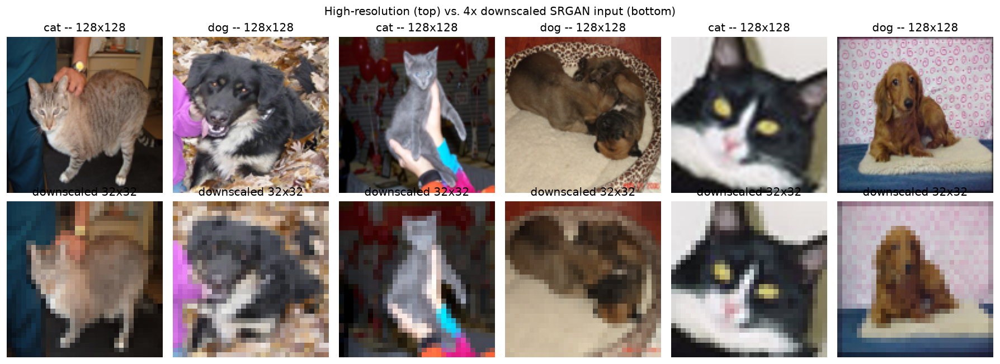

In [3]:
show("01_scaled_examples.png")

## 3. Image transformations and normalization

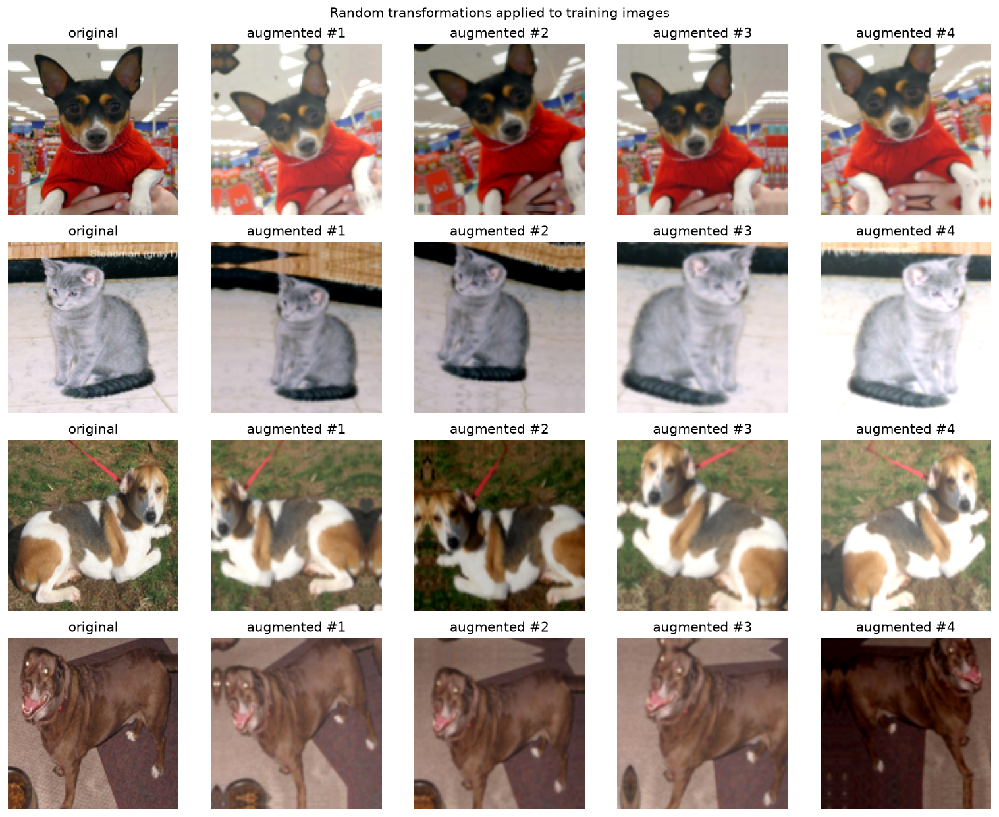

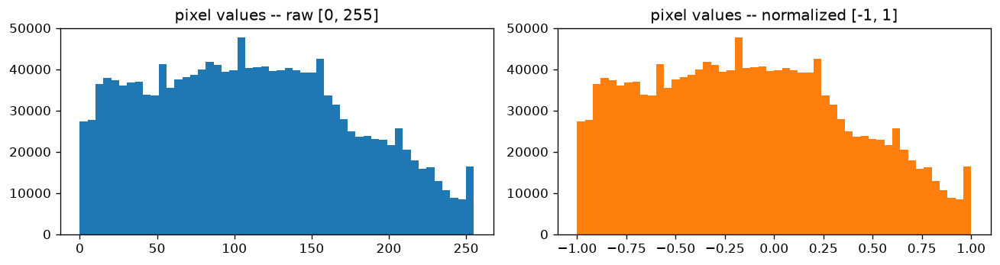

In [4]:
show("02_augmentations.png", 850); show("03_normalization.png", 850)

## 4. Model A — training curves (real 128×128 images)

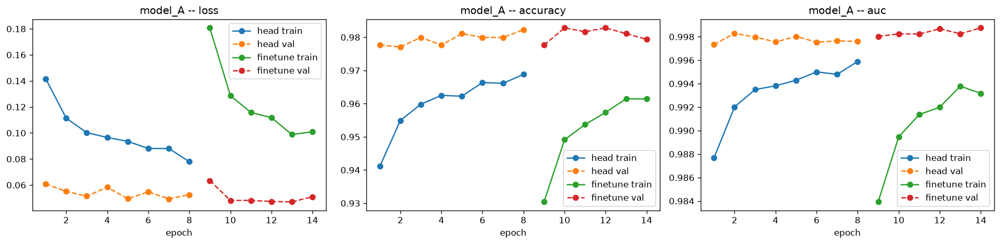

In [5]:
show("model_A_training_curves.png")

## 5. SRGAN — training losses, progress, results on test images

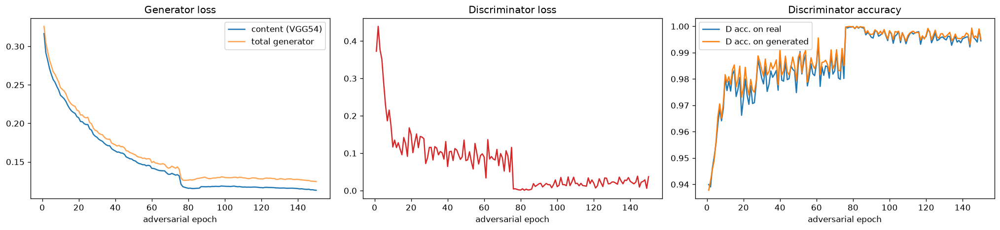

**gan_epoch_005.png**

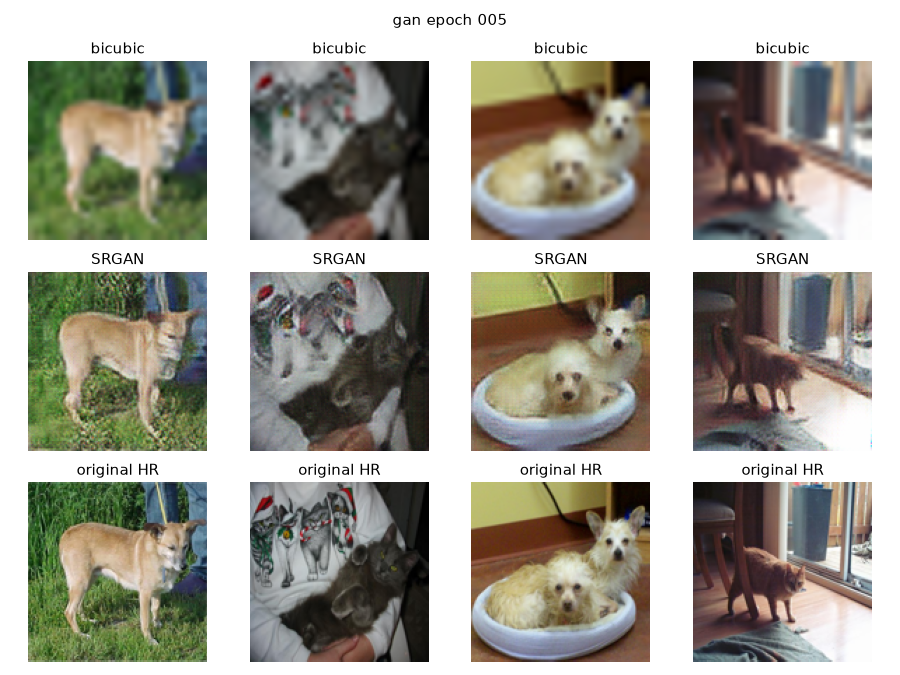

**gan_epoch_080.png**

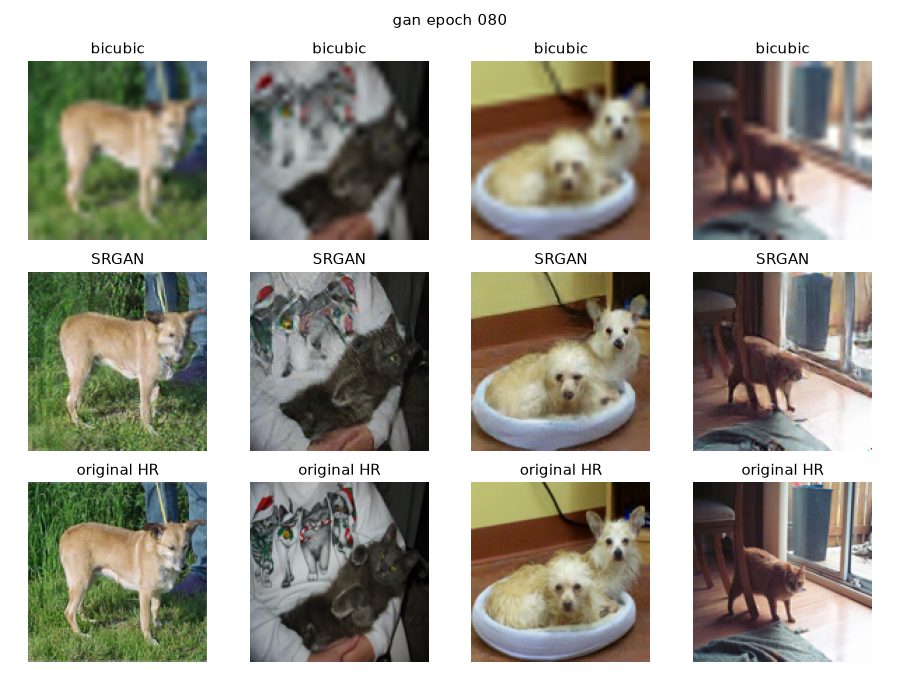

**gan_epoch_150.png**

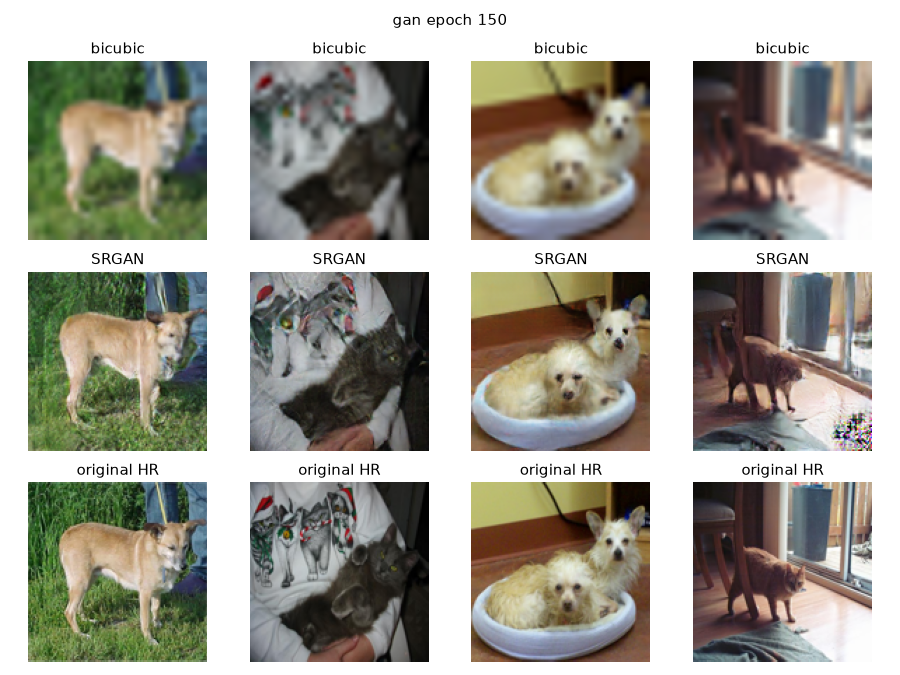

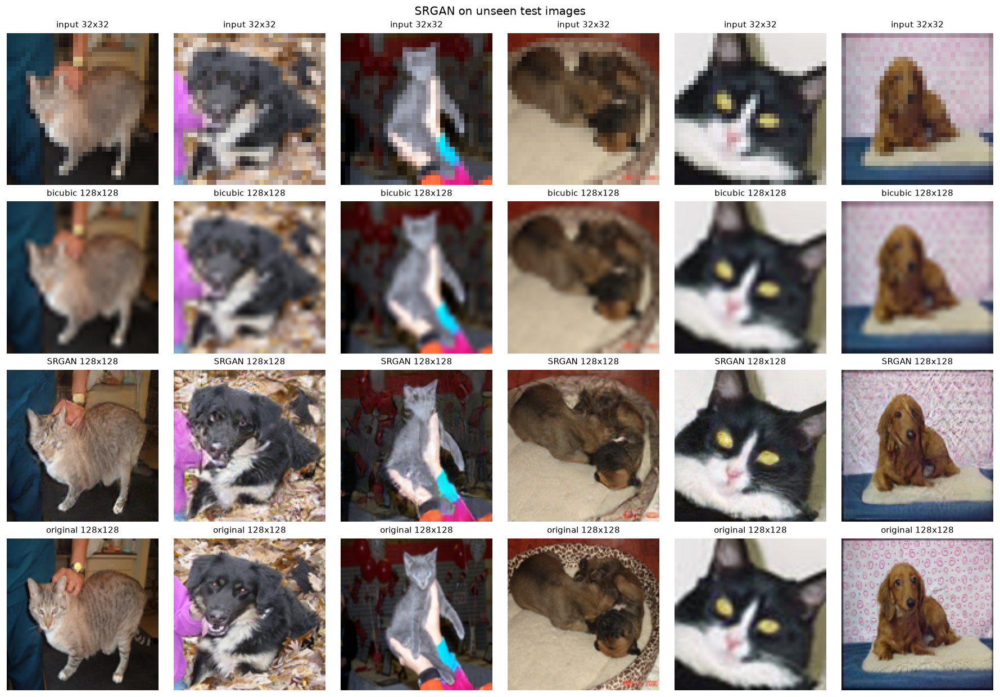

In [6]:
show("04_srgan_losses.png")
prog = sorted(glob.glob(os.path.join(FIG, "srgan_progress", "gan_epoch_*.png")))
for p in (prog[:1] + prog[len(prog) // 2: len(prog) // 2 + 1] + prog[-1:]) if prog else []:
    display(Markdown(f"**{os.path.basename(p)}**")); display(Image(p, width=650))
show("05_srgan_test_examples.png")

In [7]:
table("sr_quality_test.csv")

,method,PSNR_dB,SSIM
0,bicubic,25.0639,0.7077
1,SRGAN,23.8781,0.6582


## 6. Model B — trained on SRGAN-generated images

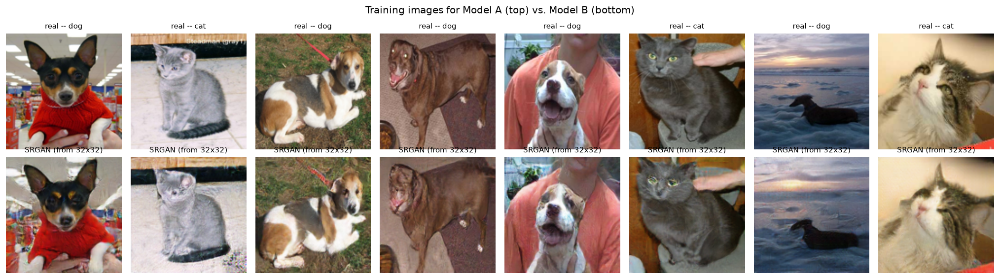

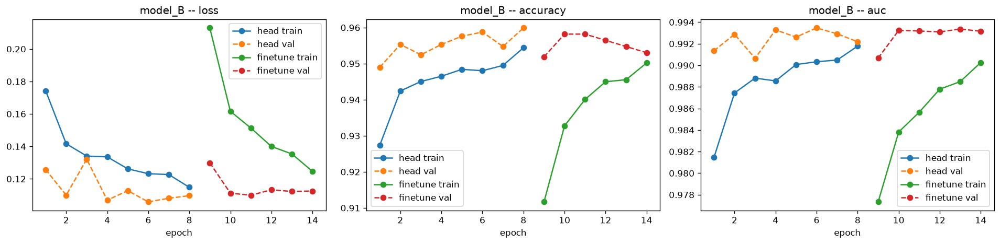

In [8]:
show("06_model_B_training_images.png"); show("model_B_training_curves.png")

## 7. Model A vs. Model B (test set, positive class = dog)

In [9]:
table("model_comparison.csv")

,model,test_images,Accuracy,Precision,Recall,F1,AUC
0,Model A,real 128x128,0.9735,0.9629,0.9850,0.9738,0.9978
1,Model A,SRGAN 128x128,0.9434,0.9315,0.9572,0.9442,0.9897
2,Model A,bicubic 128x128,0.8758,0.9480,0.7950,0.8648,0.9591
3,Model B,real 128x128,0.9729,0.9587,0.9882,0.9733,0.9974
4,Model B,SRGAN 128x128,0.9440,0.9274,0.9633,0.9450,0.9904
5,Model B,bicubic 128x128,0.8896,0.9213,0.8518,0.8852,0.9619


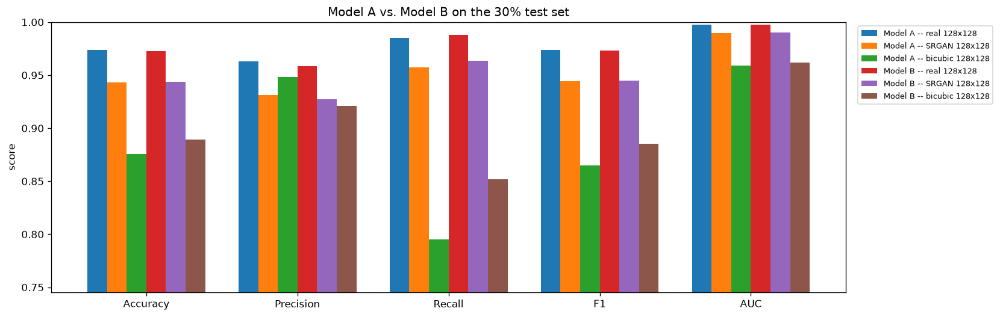

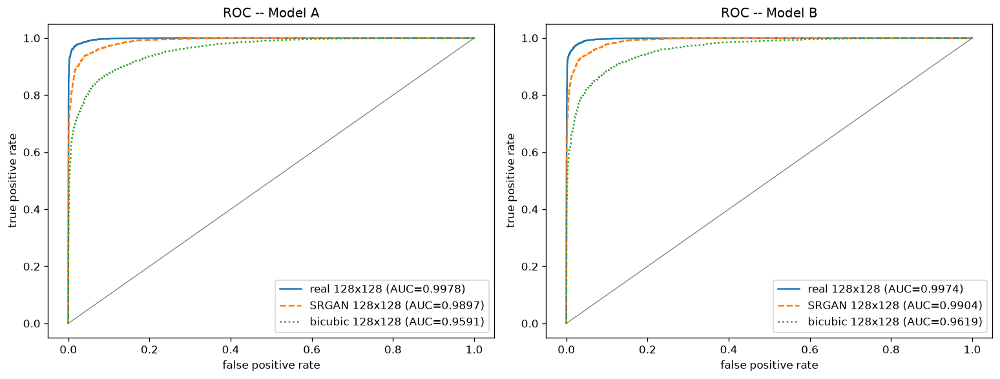

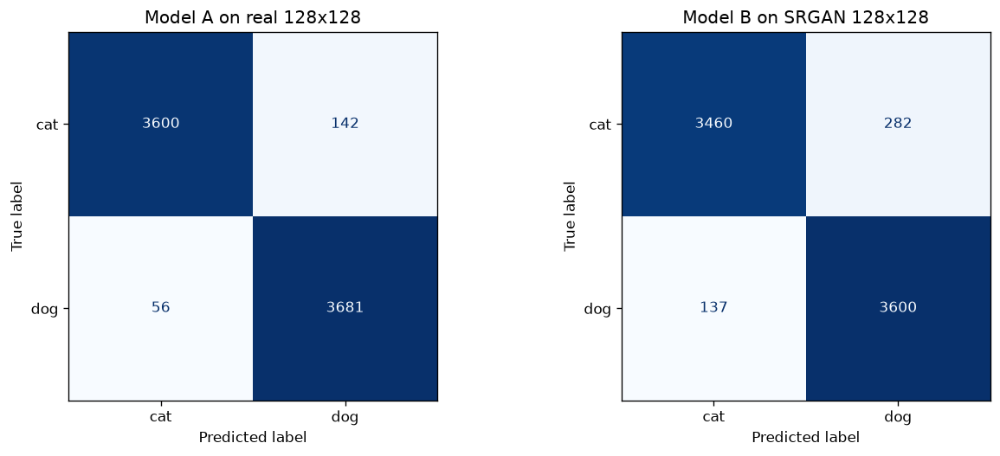

===== Model A on real 128x128 =====
              precision    recall  f1-score   support

         cat     0.9847    0.9621    0.9732      3742
         dog     0.9629    0.9850    0.9738      3737

    accuracy                         0.9735      7479
   macro avg     0.9738    0.9735    0.9735      7479
weighted avg     0.9738    0.9735    0.9735      7479

===== Model A on SRGAN 128x128 =====
              precision    recall  f1-score   support

         cat     0.9560    0.9297    0.9427      3742
         dog     0.9315    0.9572    0.9442      3737

    accuracy                         0.9434      7479
   macro avg     0.9438    0.9435    0.9434      7479
weighted avg     0.9438    0.9434    0.9434      7479

===== Model A on bicubic 128x128 =====
              precision    recall  f1-score   support

         cat     0.8237    0.9564    0.8851      3742
         dog     0.9480    0.7950    0.8648      3737

    accuracy                         0.8758      7479
   macro avg    

In [10]:
show("07_metrics_comparison.png"); show("08_roc_curves.png"); show("09_confusion_matrices.png", 850)
p = os.path.join(RES, "classification_reports.txt")
print(open(p).read() if os.path.exists(p) else "missing: " + p)